# Salud · DEIS — Atenciones de Urgencia

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Data-Observatory/datopia-notebooks/blob/main/notebooks/salud/deis-atenciones-urgencia/demo.ipynb)
[![Licencia](https://img.shields.io/badge/licencia-MIT-blue.svg)](../../../LICENSE)
[![Dataset](https://img.shields.io/badge/dataset-DEIS%20Urgencia-green.svg)]()
[![Actualización](https://img.shields.io/badge/actualización-semanal-brightgreen.svg)]()
[![Python](https://img.shields.io/badge/python-3.10%2B-blue.svg)]()

---

## Descripción

Acceso a las **Atenciones de Urgencia** del DEIS (Ministerio de Salud de Chile) a través del
**Datopia Lakehouse**: cuántas atenciones de urgencia registra cada establecimiento de la red pública
**cada día**, por causa y grupo de edad, desde 2008.

El dataset tiene dos piezas (más una tercera que se comparte con otros datasets de salud):

- **Tabla de hechos** (`tipo=atenciones-urgencia`): formato largo, una fila por (`fecha`,
  `id_establecimiento`, `id_causa`, `rango_etario`) con sus `atenciones`. Más de 400 millones de
  filas en un solo archivo Parquet **ordenado por `fecha`**, sin particiones.
- **`causas-atencion-urgencia`** (dataset hermano): el diccionario que traduce `id_causa` (dos
  dígitos) a su nombre, grupo diagnóstico, tipo de prestación y códigos CIE-10. 35 filas.
- **`establecimientos-salud`** (dataset hermano, compartido con el REM): nombre, tipo, comuna y
  región de cada establecimiento, por `id_establecimiento`.

El patrón de uso es siempre el mismo: **elegir causas en el diccionario → filtrar los hechos por un
rango de `fecha` y esas causas → sumar**, y unir a establecimientos solo si se quiere cortar por
territorio o por establecimiento.

### Contenido

1. Configuración y autenticación
2. Exploración del dataset (metadatos, cobertura, diccionario de causas)
3. Cómo buscar cualquier dato, paso a paso
4. Caso 1: el peak invernal de las consultas respiratorias (2017-2025, años completos)
5. Caso 2: consultas de urgencia por región y grupo de edad (2025)
6. Tu propia búsqueda

### Requisitos

Cuenta en el Datopia Lakehouse · Python 3.10+ · Las dependencias se instalan automáticamente

In [2]:
# @title Instalación de dependencias
import importlib, subprocess, sys

for paquete in ["requests", "duckdb", "pandas", "matplotlib"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

import json, os, getpass, pathlib
import requests, duckdb
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

EN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
pd.set_option("display.max_colwidth", 120)

print("Dependencias listas.")

Dependencias listas.


In [ ]:
# @title Configuración de credenciales
print(f"Entorno: {'Google Colab' if EN_COLAB else 'local'}")

URL_API = "https://ee98cnfz7e.execute-api.us-west-2.amazonaws.com/prod"

if EN_COLAB:
    EMAIL = input("Email: ").strip()
    PASSWORD = getpass.getpass("Contraseña: ")
else:
    ruta_cfg = pathlib.Path("../../../config.json")
    if not ruta_cfg.exists():
        raise FileNotFoundError(
            f"Archivo de configuración no encontrado en {ruta_cfg.resolve()}.\n"
            "Copia config.example.json → config.json y completa tus credenciales."
        )
    cfg = json.loads(ruta_cfg.read_text())
    EMAIL = cfg.get("test_user", {}).get("email") or input("Email: ").strip()
    PASSWORD = cfg.get("test_user", {}).get("password") or getpass.getpass(
        "Contraseña: "
    )

print(f"API    : {URL_API}")
print(f"Usuario: {EMAIL}")

---
## 1. Autenticación y conexión a S3

In [ ]:
# Iniciar sesión y obtener credenciales temporales S3
resp_login = requests.post(
    f"{URL_API}/auth/login",
    json={"email": EMAIL, "password": PASSWORD},
    timeout=30,
)
resp_login.raise_for_status()
token = resp_login.json()["id_token"]

resp_s3 = requests.post(
    f"{URL_API}/auth/session/s3",
    headers={"Authorization": f"Bearer {token}"},
    timeout=30,
)
resp_s3.raise_for_status()
creds = resp_s3.json()

print("Sesión iniciada")
print(f"  Bucket : {creds['bucket']}")
print(f"  Región : {creds['region']}")
print(f"  Expira : {creds['expires_at']}")

In [5]:
# Configurar DuckDB con credenciales S3
con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs")
con.execute(f'''
    CREATE OR REPLACE SECRET s3 (
        TYPE          S3,
        KEY_ID        '{creds["access_key_id"]}',
        SECRET        '{creds["secret_access_key"]}',
        SESSION_TOKEN '{creds["session_token"]}',
        REGION        '{creds["region"]}'
    )
''')
con.execute("SET enable_http_metadata_cache=true")
con.execute("SET parquet_metadata_cache=true")
# La lectura remota está limitada por latencia (muchas lecturas pequeñas), no por CPU:
# más hilos de E/S aceleran bastante las consultas sobre la tabla de hechos.
con.execute("SET threads=128")

BASE_FUENTE = f"s3://{creds['bucket']}/categoria=salud/pais=cl/fuente=deis"
BASE = f"{BASE_FUENTE}/tipo=atenciones-urgencia/version=v1"                # hechos
BASE_CAUSAS = f"{BASE_FUENTE}/tipo=causas-atencion-urgencia/version=v1"    # diccionario de causas
BASE_ESTAB = f"{BASE_FUENTE}/tipo=establecimientos-salud/version=v1"       # establecimientos (compartido)

# Vistas para que el SQL de las celdas siguientes se lea limpio.
# hive_partitioning=false: la ruta lleva categoria=/fuente=/tipo=..., que no son columnas de los datos.
con.execute(f'''CREATE OR REPLACE VIEW urgencias AS
    SELECT * FROM read_parquet('{BASE}/part*.parquet', hive_partitioning=false)''')
con.execute(f'''CREATE OR REPLACE VIEW causas AS
    SELECT * FROM read_parquet('{BASE_CAUSAS}/part-*.parquet', hive_partitioning=false)''')
# De establecimientos solo se usan columnas descriptivas (la tabla tiene ~40)
con.execute(f'''CREATE OR REPLACE VIEW establecimientos AS
    SELECT id_establecimiento, nombre_establecimiento, tipo_establecimiento,
           cut_com, nom_com, nom_reg, nombre_servicio_salud
    FROM read_parquet('{BASE_ESTAB}/part-*.parquet', hive_partitioning=false)''')
print("DuckDB conectado a S3. Vistas: urgencias, causas, establecimientos")

DuckDB conectado a S3. Vistas: urgencias, causas, establecimientos


---
## 2. Exploración del dataset

In [6]:
# Metadatos del dataset (dataset.json en la raíz del path S3)
meta = (
    con.execute(f"SELECT * FROM read_json('{BASE}/dataset.json')")
    .df()
    .iloc[0]
    .to_dict()
)

print(meta["description"][:600] + "...")
print()
print(f"Formato      : {meta['format']}")
print(f"Particiones  : {list(meta.get('partitioned_by') or meta.get('partition_keys')) or 'ninguna'}")
print(f"Clave        : {list(meta['primary_key'])}")

pd.DataFrame([dict(c) for c in meta["columns"]])[["name", "type", "comment"]]

Daily emergency-care visits (Atenciones de Urgencia) reported by the establishments of the Chilean public health network to DEIS (Ministry of Health), 2008 onwards, in long format: one row per date, establishment, cause and age group with the number of visits. The section and group total rows of the source are dropped by cause code so that nothing is counted twice; the filter uses the code, not the label. The cause labels are in tipo=causas-atencion-urgencia. Superseded establishment codes are mapped to the current code with tipo=establecimientos-salud-historial. If the source repeats a (fecha...

Formato      : parquet
Particiones  : ninguna
Clave        : ['fecha', 'id_establecimiento', 'id_causa', 'rango_etario']


,name,type,comment
0,year,int,Calendar year of fecha.
1,semana,smallint,Epidemiological week as reported by the source.
2,fecha,date,"Date of the visits (source dd/mm/yyyy, no time)."
3,id_establecimiento,string,Current DEIS establishment code (superseded codes mapped with tipo=establecimientos-salud-historial); references tip...
4,id_causa,string,Two-digit cause code; references tipo=causas-atencion-urgencia.id_causa.
5,rango_etario,string,"Age group of the patients: menores 1, de 1 a 4, de 5 a 14, de 15 a 64, de 65 y mas."
6,atenciones,int,"Number of emergency-care visits for the date, establishment, cause and age group."
7,tipo_campana,string,"Seasonal campaign in force for the establishment and date, as reported by the source in lowercase (e.g. ninguna, inv..."
8,flags_procesamiento,int,"Bit flags of ETL transformations (value = sum of set bits): 1 base value, 32 repeated source key collapsed."


In [7]:
# Cobertura: manifest.json resume el archivo publicado (filas, bytes, primera y última fecha)
manifest = con.execute(f"SELECT * FROM read_json('{BASE}/manifest.json')").df().iloc[0]

print(f"Filas totales : {manifest['row_count']:,}".replace(",", "."))
print(f"Desde / hasta : {str(manifest['first_date'])[:10]} → {str(manifest['last_date'])[:10]}")
print(f"Publicado     : {manifest['created_at_utc']} (UTC)")
pd.DataFrame([dict(p) for p in manifest["parts"]]).assign(MB=lambda d: (d["bytes"] / 1e6).round(0))

Filas totales : 425.481.375
Desde / hasta : 2008-01-03 → 2026-11-16
Publicado     : 2026-11-18 15:59:58 (UTC)


,file,row_count,bytes,MB
0,part00000.parquet,425481375,109953002,110.0


El archivo está ordenado por `fecha` y cada mes cierra su último *row group* (bloque de hasta 75.000
filas), así que ningún bloque mezcla dos años. Por eso las **filas por año** se pueden contar con las
estadísticas del pie del Parquet (`parquet_metadata`), sin leer los datos:

In [8]:
filas_por_anio = con.sql(f'''
    SELECT year(stats_min::DATE)  AS year,
           CAST(SUM(row_group_num_rows) AS BIGINT) AS filas,
           COUNT(*)                                 AS row_groups
    FROM parquet_metadata('{BASE}/part*.parquet')
    WHERE path_in_schema = 'fecha'
    GROUP BY 1 ORDER BY 1
''').df()
filas_por_anio.set_index("year").T

year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
filas,1099560,5740660,12333215,14311660,15465890,16456770,16842100,17683050,18070580,18150330,18247900,18500460,27182690,37469020,37936800,37820410,38136100,38807205,35226975
row_groups,22,84,170,197,214,225,233,243,247,246,249,252,369,505,509,511,516,522,477


Las filas crecen en 2020 porque la fuente agrega causas nuevas (COVID-19, salud mental) y más
establecimientos informan. Las filas no son atenciones: cada fila es una combinación (fecha,
establecimiento, causa, edad), y muchas valen 0.

### El diccionario `causas-atencion-urgencia`

La tabla de hechos solo trae `id_causa` (`'04'`, `'34'`...). El diccionario lo traduce. Cada causa
tiene un **grupo diagnóstico** (sistema respiratorio, circulatorio, traumatismos, trastornos
mentales...) y un **tipo de prestación** (consulta, hospitalización o cirugía):

In [9]:
diccionario = con.sql('''
    SELECT id_causa, tipo_prestacion, grupo_diagnostico, nombre_causa, codigo_cie10
    FROM causas
    ORDER BY tipo_prestacion, grupo_diagnostico, id_causa
''').df()
diccionario

,id_causa,tipo_prestacion,grupo_diagnostico,nombre_causa,codigo_cie10
0,24,cirugía,todos,cirugías de urgencia,NaN
1,43,consulta,43,"lesiones por quemaduras, exposición al humo, fuego, llamas, contacto con calor y sustancias calientes",causa externa x00-x19
2,21,consulta,otras causas,otras causas,"s00-t98, v90-y98"
3,13,consulta,sistema circulatorio,infarto agudo miocardio,i21-i22
4,14,consulta,sistema circulatorio,accidente vascular encefálico,"i60-i66, i167.8-167.9"
5,15,consulta,sistema circulatorio,crisis hipertensiva,i10.x
6,16,consulta,sistema circulatorio,arritmia grave,"i44-i46.0, i46.9-i49"
7,17,consulta,sistema circulatorio,otras causas,"i00-i09, i11-i15, i20, i23-i28, i30-i42, i50-i52, i67.0-i67.7, i69-i99"
8,29,consulta,sistema digestivo,diarrea aguda,a00-a09
9,03,consulta,sistema respiratorio,bronquitis/bronquiolitis aguda,j20-j21


**Ojo: no todas las causas se pueden sumar entre sí.** La fuente ya trae algunos totales:

| `id_causa` | Qué es | Cuidado |
|---|---|---|
| `34` *total demanda* | **todas** las consultas de urgencia | sumarla con las demás causas cuenta dos veces |
| `07`, `22`, `23` (nombre *total*) | hospitalizaciones de un grupo (respiratorio, circulatorio, traumatismos) | son el total del grupo; `32`/`33` (COVID-19) son hospitalizaciones respiratorias |
| `27`, `28` | pacientes en espera de hospitalización; `28` es el subconjunto que espera menos de 12 horas | no sumar entre sí |

Las consultas por causa específica no suman el total de `34` (en 2023: 19,2 millones contra 21,0):
la fuente no clasifica toda consulta en una causa. Para "todas las consultas" usar `34`; para un
grupo, sumar sus causas específicas (dentro de un mismo tipo de prestación).

**No todas las causas existen en todos los años.** `34` (*total demanda*), las de COVID-19 (`30` a
`33`), las de salud mental (`37` a `42`) y las lesiones autoinfligidas (`35`) aparecen desde 2020; las
quemaduras (`43`), desde 2025. Antes de 2020 no hay un total de consultas: una serie larga tiene que
sumar causas que existan en todo el período.

### Las columnas de los hechos

Un día cualquiera de un establecimiento, ya con el nombre de la causa:

In [10]:
con.sql('''
    SELECT u.fecha, u.year, u.semana, u.id_establecimiento, u.id_causa, c.nombre_causa,
           u.rango_etario, u.atenciones, u.tipo_campana, u.flags_procesamiento
    FROM urgencias u
    JOIN causas c USING (id_causa)
    WHERE u.fecha = DATE '2025-07-01'
      AND u.id_establecimiento = (SELECT MIN(id_establecimiento) FROM urgencias
                                  WHERE fecha = DATE '2025-07-01')
      AND u.id_causa IN ('10', '34')
    ORDER BY u.id_causa, u.rango_etario
''').df()

,fecha,year,semana,id_establecimiento,id_causa,nombre_causa,rango_etario,atenciones,tipo_campana,flags_procesamiento
0,2025-07-01,2025,27,101100,10,ira alta,de 1 a 4,14,ninguna,1
1,2025-07-01,2025,27,101100,10,ira alta,de 15 a 64,28,ninguna,1
2,2025-07-01,2025,27,101100,10,ira alta,de 5 a 14,17,ninguna,1
3,2025-07-01,2025,27,101100,10,ira alta,de 65 y mas,3,ninguna,1
4,2025-07-01,2025,27,101100,10,ira alta,menores 1,2,ninguna,1
5,2025-07-01,2025,27,101100,34,total demanda,de 1 a 4,57,ninguna,1
6,2025-07-01,2025,27,101100,34,total demanda,de 15 a 64,207,ninguna,1
7,2025-07-01,2025,27,101100,34,total demanda,de 5 a 14,74,ninguna,1
8,2025-07-01,2025,27,101100,34,total demanda,de 65 y mas,58,ninguna,1
9,2025-07-01,2025,27,101100,34,total demanda,menores 1,19,ninguna,1


- **`rango_etario`**: cinco grupos de edad, siempre los mismos (`menores 1`, `de 1 a 4`,
  `de 5 a 14`, `de 15 a 64`, `de 65 y mas`). Como texto no se ordenan solos: hay que darles orden
  a mano (ver `ORDEN_EDAD` más abajo).
- **`semana`**: la semana epidemiológica que informa la fuente (de domingo a sábado). En los últimos
  días de diciembre puede valer `1` (la primera semana del año siguiente) mientras `year` sigue
  siendo el año calendario de `fecha`. Para series semanales hay que usar el año epidemiológico
  (`anio_epi` en la sección 3), no `year`.
- **`tipo_campana`**: campaña estacional vigente para el establecimiento y la fecha (`ninguna`,
  `invierno regiones`, `sapu metropolitana`...).
- **`flags_procesamiento`**: uso técnico. `1` es el valor normal; `33` marca una fila cuya clave venía
  repetida en la fuente y se dejó la última línea del archivo (unas 80 mil filas de 2009-2024).

---
## 3. Cómo buscar cualquier dato, paso a paso

No hace falta conocer los códigos. Se parte de una **palabra** (o de un grupo diagnóstico) en el
diccionario y se suman los hechos de esas causas en un rango de fechas.

| Paso | Pregunta | Función | Lee |
|---|---|---|---|
| 1 | ¿Qué causas mencionan la palabra o son de ese grupo? | `buscar_causas(texto, grupo, tipo)` | `causas` (instantáneo) |
| 2 | Traer los datos, agregados como se pida | `atenciones(causas, desde, hasta, por)` | `urgencias` (segundos a un minuto) |

`por` es la lista de columnas por las que agrupar: de los hechos (`fecha`, `year`, `semana`,
`anio_epi`, `rango_etario`, `id_causa`, `id_establecimiento`, `tipo_campana`), del diccionario
(`nombre_causa`, `grupo_diagnostico`, `tipo_prestacion`) o de establecimientos
(`nombre_establecimiento`, `tipo_establecimiento`, `nom_com`, `cut_com`, `nom_reg`, `cut_reg`,
`nombre_servicio_salud`). La función une el diccionario y establecimientos solo si hacen falta.

**Consejo:** acotar siempre `desde`/`hasta`. El archivo está ordenado por `fecha`, así que DuckDB lee
solo los bloques de ese rango; un año entero toma unos segundos, toda la tabla bastante más.

In [11]:
def buscar_causas(texto=None, grupo=None, tipo=None):
    '''Paso 1: causas cuyo nombre, grupo o códigos CIE-10 contienen `texto`, filtradas por grupo y tipo.'''
    return con.execute(
        '''
        SELECT id_causa, tipo_prestacion, grupo_diagnostico, nombre_causa, codigo_cie10
        FROM causas
        WHERE (? IS NULL OR nombre_causa ILIKE ? OR grupo_diagnostico ILIKE ? OR codigo_cie10 ILIKE ?)
          AND (? IS NULL OR grupo_diagnostico = ?)
          AND (? IS NULL OR tipo_prestacion = ?)
        ORDER BY id_causa
        ''',
        [texto] + [f"%{texto}%"] * 3 + [grupo, grupo, tipo, tipo],
    ).df()


# Columnas que acepta `por`, con la expresión SQL que las calcula
_COLUMNAS = {
    # hechos (alias u)
    "fecha": "u.fecha", "year": "u.year", "semana": "u.semana",
    # Año epidemiológico: el de la fecha del miércoles de la semana (domingo a sábado)
    "anio_epi": "year(u.fecha - CAST(dayofweek(u.fecha) AS INTEGER) + 3)",
    "rango_etario": "u.rango_etario", "id_causa": "u.id_causa",
    "id_establecimiento": "u.id_establecimiento", "tipo_campana": "u.tipo_campana",
    # diccionario de causas (alias c)
    "nombre_causa": "c.nombre_causa", "grupo_diagnostico": "c.grupo_diagnostico",
    "tipo_prestacion": "c.tipo_prestacion",
    # establecimientos (alias e)
    "nombre_establecimiento": "e.nombre_establecimiento",
    "tipo_establecimiento": "e.tipo_establecimiento", "nom_com": "e.nom_com",
    "cut_com": "e.cut_com", "nom_reg": "e.nom_reg", "cut_reg": "left(e.cut_com, 2)",
    "nombre_servicio_salud": "e.nombre_servicio_salud",
}


def atenciones(causas, desde, hasta, por=("fecha",)):
    '''Paso 2: suma de `atenciones` de las causas entre dos fechas (inclusive), agrupada por `por`.

    `causas` es una lista de id_causa o el DataFrame que devuelve buscar_causas.
    '''
    ids = list(causas["id_causa"]) if isinstance(causas, pd.DataFrame) else list(causas)
    desconocidas = [c for c in por if c not in _COLUMNAS]
    if desconocidas:
        raise ValueError(f"Columnas no reconocidas en `por`: {desconocidas}")
    select = ", ".join(f"{_COLUMNAS[c]} AS {c}" for c in por)
    uniones = ""
    if any(_COLUMNAS[c].startswith("c.") for c in por):
        uniones += " JOIN causas c ON c.id_causa = u.id_causa"
    if any(_COLUMNAS[c].startswith("e.") or "(e." in _COLUMNAS[c] for c in por):
        # LEFT JOIN: un establecimiento sin ficha no hace desaparecer sus atenciones
        uniones += " LEFT JOIN establecimientos e ON e.id_establecimiento = u.id_establecimiento"
    marcadores = ", ".join("?" for _ in ids)
    return con.execute(
        f'''
        SELECT {select}, SUM(u.atenciones) AS atenciones
        FROM urgencias u{uniones}
        WHERE u.fecha BETWEEN ? AND ?
          AND u.id_causa IN ({marcadores})
        GROUP BY ALL
        ORDER BY ALL
        ''',
        [desde, hasta] + ids,
    ).df()


ORDEN_EDAD = ["menores 1", "de 1 a 4", "de 5 a 14", "de 15 a 64", "de 65 y mas"]
miles = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
print("Funciones listas: buscar_causas, atenciones")

Funciones listas: buscar_causas, atenciones


---
## 4. Caso 1: el peak invernal de las consultas respiratorias

Pregunta: **¿cuántas consultas de urgencia por causas respiratorias hay cada semana, y cómo cambia
el peak de invierno de un año a otro?**

### Paso 1: las causas respiratorias que son consultas

In [12]:
RESPIRATORIAS = buscar_causas(grupo="sistema respiratorio", tipo="consulta")
RESPIRATORIAS

,id_causa,tipo_prestacion,grupo_diagnostico,nombre_causa,codigo_cie10
0,03,consulta,sistema respiratorio,bronquitis/bronquiolitis aguda,j20-j21
1,04,consulta,sistema respiratorio,influenza,j09-j11
2,05,consulta,sistema respiratorio,neumonía,j12-j18
3,06,consulta,sistema respiratorio,otra causa respiratoria no contenidas en las categorías anteriores,"j22, j30-j39, j47, j60-j98"
4,10,consulta,sistema respiratorio,ira alta,j00-j06
5,11,consulta,sistema respiratorio,crisis obstructiva bronquial,j40-j46
6,30,consulta,sistema respiratorio,"covid-19, virus identificado",u07.1
7,31,consulta,sistema respiratorio,"covid-19, virus no identificado",u07.2


Son 8 causas específicas: IRA alta, bronquitis, influenza, neumonía, crisis obstructiva, otras
respiratorias y las dos de COVID-19 (que existen desde 2020). Ninguna es un total, así que se pueden
sumar. (Las hospitalizaciones respiratorias, `07`, `32` y `33`, quedan fuera por ser otro tipo de
prestación.)

### Paso 2: la serie semanal, 2017-2025

Una sola consulta trae las 8 causas agrupadas por año epidemiológico y semana. Lee 9 años de la tabla
de hechos (solo las columnas necesarias): **toma del orden de un minuto**.

In [13]:
resp_semanal = atenciones(RESPIRATORIAS, "2017-01-01", "2026-01-03", por=("anio_epi", "semana"))
# Las semanas epidemiológicas no calzan con el año calendario: el rango va del domingo 2017-01-01
# (inicio de la semana 1 de 2017) al sábado 2026-01-03 (fin de la semana 53 de 2025)
print(f"Filas: {len(resp_semanal)} (año epidemiológico × semana)")

# Total anual y semana del peak de cada año
peaks = resp_semanal.loc[resp_semanal.groupby("anio_epi")["atenciones"].idxmax()].set_index("anio_epi")
resumen = pd.DataFrame({
    "consultas_en_el_anio": resp_semanal.groupby("anio_epi")["atenciones"].sum().astype(int),
    "semana_peak": peaks["semana"],
    "consultas_semana_peak": peaks["atenciones"].astype(int),
})
resumen

Filas: 470 (año epidemiológico × semana)


,consultas_en_el_anio,semana_peak,consultas_semana_peak
anio_epi,,,
2017,5126298,23,181754
2018,4910356,33,144380
2019,4981038,21,164729
2020,2291654,12,107373
2021,3460772,46,89904
2022,7356890,5,203124
2023,5861662,20,193704
2024,5574887,20,203869
2025,5214535,21,139463


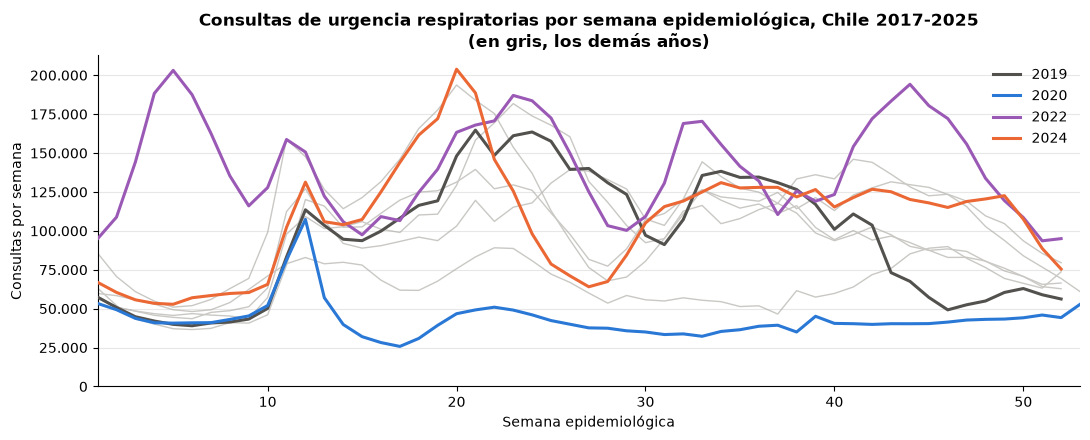

In [14]:
DESTACADOS = {2019: "#52514e", 2020: "#2a78d6", 2022: "#9b59b6", 2024: "#eb6834"}

fig, ax = plt.subplots(figsize=(11, 4.5))
for anio, grupo in resp_semanal.groupby("anio_epi"):
    destacado = anio in DESTACADOS
    ax.plot(grupo["semana"], grupo["atenciones"],
            label=str(anio) if destacado else None,
            color=DESTACADOS.get(anio, "#c9c8c4"),
            linewidth=2.2 if destacado else 1.0, zorder=3 if destacado else 1)

ax.set_title("Consultas de urgencia respiratorias por semana epidemiológica, Chile 2017-2025\n"
             "(en gris, los demás años)", fontweight="bold")
ax.set_xlabel("Semana epidemiológica")
ax.set_ylabel("Consultas por semana")
ax.yaxis.set_major_formatter(miles)
ax.set_xlim(1, 53)
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

En los años sin pandemia (2017-2019 y 2023-2025) el peak cae entre mayo y agosto (semanas 20 a 33):
en 2023 y 2024 llegó en la semana 20, a mediados de mayo, y en 2018 recién en la 33. La pandemia
rompe el patrón: en **2020** el máximo es la semana 12 (marzo, inicio de la pandemia) y después las
consultas se desploman, sin peak invernal; **2021** sigue bajo; y el máximo de toda la serie es la
semana 5 de **2022**, la ola Ómicron (en esa semana, casi tres de cada cuatro consultas respiratorias
fueron por COVID-19).

### ¿Qué causa explica el peak? (2024-2025)

Mismo paso 2, agrupando también por causa:

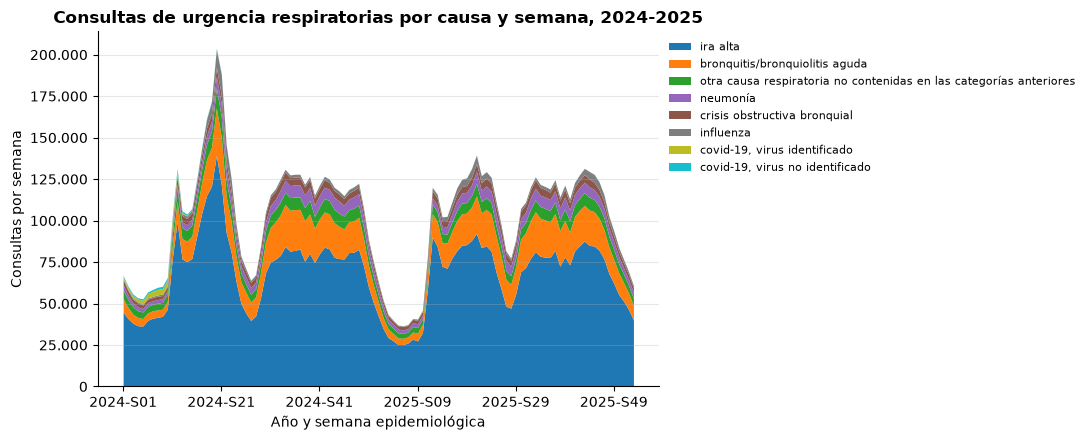

etiqueta,2024,2025
% del año,,
ira alta,67.1,66.4
bronquitis/bronquiolitis aguda,15.0,16.1
otra causa respiratoria no contenidas en las categorías anteriores,6.4,5.9
neumonía,4.7,5.3
crisis obstructiva bronquial,3.6,3.8
influenza,2.2,2.4
"covid-19, virus identificado",0.6,0.0
"covid-19, virus no identificado",0.4,0.0


In [15]:
por_causa = atenciones(RESPIRATORIAS, "2023-12-31", "2026-01-03",
                       por=("anio_epi", "semana", "nombre_causa"))
por_causa["etiqueta"] = por_causa["anio_epi"].astype(str) + "-S" + por_causa["semana"].astype(str).str.zfill(2)

tabla = por_causa.pivot_table(index="etiqueta", columns="nombre_causa", values="atenciones", aggfunc="sum")
tabla = tabla[tabla.sum().sort_values(ascending=False).index]   # causas de mayor a menor

fig, ax = plt.subplots(figsize=(11, 4.5))
tabla.plot.area(ax=ax, linewidth=0, colormap="tab10")
ax.set_title("Consultas de urgencia respiratorias por causa y semana, 2024-2025", fontweight="bold")
ax.set_xlabel("Año y semana epidemiológica")
ax.set_ylabel("Consultas por semana")
ax.yaxis.set_major_formatter(miles)
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Participación de cada causa en el año
(tabla.groupby(tabla.index.str[:4]).sum().T
 .pipe(lambda t: (100 * t / t.sum()).round(1))
 .rename_axis("% del año"))

La IRA alta (resfrío, faringitis, amigdalitis) es dos tercios del volumen todo el año. En el peak
(semanas 18 a 30 de 2024) la influenza más que triplica su promedio del resto del año y la
bronquitis/bronquiolitis sube cerca de un 20 %; la IRA alta sube menos en proporción (~13 %), pero por
su volumen aporta la mayor parte de las consultas extra. COVID-19 ya casi no aparece en 2025.

---
## 5. Caso 2: consultas de urgencia por región y grupo de edad

Pregunta: **¿cómo se reparten por edad las consultas de urgencia de cada región?**

Aquí interesan **todas** las consultas, así que se usa la causa `34` (*total demanda*), sola. La región
no está en los hechos: sale de unir `id_establecimiento` con `establecimientos-salud` (la función lo
hace sola al pedir `cut_reg`). Los dos primeros dígitos del código de comuna (`cut_com`) son el código
de región.

In [16]:
TOTAL_CONSULTAS = ["34"]
ANIO = 2025

region_edad = atenciones(TOTAL_CONSULTAS, f"{ANIO}-01-01", f"{ANIO}-12-31",
                         por=("cut_reg", "rango_etario"))
sin_region = region_edad.loc[region_edad["cut_reg"].isna(), "atenciones"].sum()
print(f"Consultas {ANIO}: {region_edad['atenciones'].sum():,.0f}".replace(",", ".")
      + f" (sin establecimiento en la ficha: {sin_region:,.0f})".replace(",", "."))

# Regiones de norte a sur (por código) con nombre corto
REGIONES = {
    "15": "Arica y Parinacota", "01": "Tarapacá", "02": "Antofagasta", "03": "Atacama",
    "04": "Coquimbo", "05": "Valparaíso", "13": "Metropolitana", "06": "O'Higgins",
    "07": "Maule", "16": "Ñuble", "08": "Biobío", "09": "Araucanía", "14": "Los Ríos",
    "10": "Los Lagos", "11": "Aysén", "12": "Magallanes",
}
por_region = (
    region_edad.dropna(subset=["cut_reg"])
    .pivot_table(index="cut_reg", columns="rango_etario", values="atenciones", aggfunc="sum")
    .reindex(index=list(REGIONES), columns=ORDEN_EDAD)
    .rename(index=REGIONES)
)
por_region.assign(total=por_region.sum(axis=1)).astype(int)

Consultas 2025: 21.167.612 (sin establecimiento en la ficha: 0)


rango_etario,menores 1,de 1 a 4,de 5 a 14,de 15 a 64,de 65 y mas,total
cut_reg,,,,,,
Arica y Parinacota,6740,22404,36629,116582,31482,213837
Tarapacá,16048,53435,94042,330027,57615,551167
Antofagasta,14823,50349,92391,361050,62781,581394
Atacama,8182,33297,70264,226882,52956,391581
Coquimbo,16209,62517,138033,468363,125118,810240
Valparaíso,40008,153817,345566,1212186,343436,2095013
Metropolitana,148796,526529,1065804,3850875,1003440,6595444
O'Higgins,23284,90153,205092,780607,203515,1302651
Maule,35034,149279,313017,1101806,298137,1897273


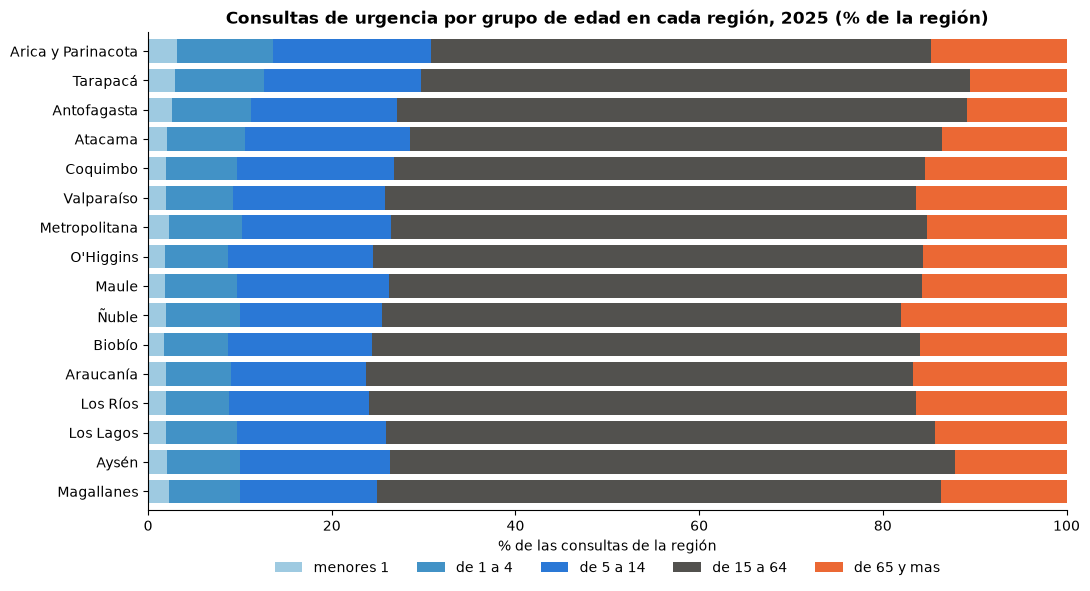

rango_etario,menores 1,de 1 a 4,de 5 a 14,de 15 a 64,de 65 y mas
cut_reg,,,,,
Arica y Parinacota,3.2,10.5,17.1,54.5,14.7
Tarapacá,2.9,9.7,17.1,59.9,10.5
Antofagasta,2.5,8.7,15.9,62.1,10.8
Atacama,2.1,8.5,17.9,57.9,13.5
Coquimbo,2.0,7.7,17.0,57.8,15.4
Valparaíso,1.9,7.3,16.5,57.9,16.4
Metropolitana,2.3,8.0,16.2,58.4,15.2
O'Higgins,1.8,6.9,15.7,59.9,15.6
Maule,1.8,7.9,16.5,58.1,15.7


In [17]:
porcentaje = 100 * por_region.div(por_region.sum(axis=1), axis=0)
COLORES_EDAD = ["#9ecae1", "#4292c6", "#2a78d6", "#52514e", "#eb6834"]

fig, ax = plt.subplots(figsize=(11, 6))
porcentaje.plot.barh(stacked=True, ax=ax, color=COLORES_EDAD, width=0.8)
ax.invert_yaxis()
ax.set_title(f"Consultas de urgencia por grupo de edad en cada región, {ANIO} (% de la región)",
             fontweight="bold")
ax.set_xlabel("% de las consultas de la región")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

porcentaje.round(1)

El grupo de 15 a 64 años es siempre la mayoría (entre 54 % y 62 %). El peso de los mayores de 65
cambia bastante entre regiones (de ~11 % en Tarapacá y Antofagasta a 18 % en Ñuble), en parte porque
la estructura de edad de la población es distinta: para comparar regiones en serio hay que dividir
por la población de cada grupo (por ejemplo, con el censo 2024 del INE, notebook `sociologia/ine`).
`34` existe desde 2020, así que este corte sirve para 2020 en adelante.

### Los establecimientos con más consultas

Misma función, agrupando por establecimiento (con su nombre y comuna):

In [18]:
top = atenciones(TOTAL_CONSULTAS, f"{ANIO}-01-01", f"{ANIO}-12-31",
                 por=("id_establecimiento", "nombre_establecimiento", "tipo_establecimiento",
                      "nom_com", "cut_reg"))
top["region"] = top["cut_reg"].map(REGIONES)
(top.sort_values("atenciones", ascending=False)
    .head(10)
    .drop(columns="cut_reg")
    .assign(atenciones=lambda d: d["atenciones"].astype(int))
    .reset_index(drop=True))

,id_establecimiento,nombre_establecimiento,tipo_establecimiento,nom_com,atenciones,region
0,114101,complejo hospitalario dr. sotero del rio,hospital,puente alto,168351,Metropolitana
1,121109,hospital dr. hernan henriquez aravena,hospital,temuco,150581,Araucanía
2,101100,hospital regional dr. juan noe crevani,hospital,arica,150158,Arica y Parinacota
3,110120,hospital felix bulnes cerda,hospital,cerro navia,142773,Metropolitana
4,107100,hospital dr. gustavo fricke,hospital,viña del mar,133911,Valparaíso
5,118100,hospital clinico regional dr. guillermo grant benavente,hospital,concepcion,133533,Biobío
6,114103,hospital padre alberto hurtado,hospital,san ramon,130607,Metropolitana
7,120101,complejo asistencial dr. victor rios ruiz,hospital,los angeles,130120,Biobío
8,115100,hospital dr. franco ravera zunino,hospital,rancagua,126383,O'Higgins
9,119100,hospital las higueras,hospital,talcahuano,116252,Biobío


---
## 6. Tu propia búsqueda

Cambia `TEXTO` y ejecuta las celdas en orden. El ejemplo busca las causas de salud mental, que la
fuente informa desde 2020.

In [19]:
TEXTO = "mental"  # palabra a buscar (en el nombre, el grupo o los códigos CIE-10)

MIS_CAUSAS = buscar_causas(TEXTO)
MIS_CAUSAS

,id_causa,tipo_prestacion,grupo_diagnostico,nombre_causa,codigo_cie10
0,37,consulta,trastornos mentales,ideación suicida,r45.8
1,38,consulta,trastornos mentales,trastornos mentales y del comportamiento debidos al uso de sustancias psicoactivas,f10-f19
2,39,consulta,trastornos mentales,trastornos del humor afectivos,f30-f39
3,40,consulta,trastornos mentales,"trastornos neuróticos, trastornos relacionados con el estrés y trastornos somatomorfos",f40-f48
4,41,consulta,trastornos mentales,otros trastornos mentales no contenidos en las categorías anteriores,NaN
5,42,hospitalización,trastornos mentales,causa por trastornos mentales,f00-f99


In [20]:
# Quedarse con un solo tipo de prestación: mezclar consultas y hospitalizaciones no tiene sentido
MIS_CAUSAS = MIS_CAUSAS[MIS_CAUSAS["tipo_prestacion"] == "consulta"]

# Un año tarda unos segundos; varios años, más. Agrupa por lo que necesites (ver `por` en la sección 3).
mi_serie = atenciones(MIS_CAUSAS, "2021-01-01", "2025-12-31", por=("year", "nombre_causa"))
mi_serie.pivot_table(index="nombre_causa", columns="year", values="atenciones", aggfunc="sum").astype("Int64")

year,2021,2022,2023,2024,2025
nombre_causa,,,,,
ideación suicida,6200,9087,11113,12433,15733
otros trastornos mentales no contenidos en las categorías anteriores,50590,70550,71879,59801,61709
trastornos del humor afectivos,18456,25476,29109,30634,32146
trastornos mentales y del comportamiento debidos al uso de sustancias psicoactivas,27335,29741,29438,28633,29317
"trastornos neuróticos, trastornos relacionados con el estrés y trastornos somatomorfos",133584,147354,169676,173930,189053


### Notas

- **No sumar todas las causas.** La causa `34` (*total demanda*, desde 2020) ya es el total de consultas; las de
  nombre *total* (`07`, `22`, `23`) son totales de hospitalización por grupo; `28` es parte de `27`.
  Sumar siempre causas de un mismo tipo de prestación y sin mezclar totales con sus partes. (Los
  totales de sección y de grupo de la fuente ya vienen quitados por código.)
- **Causas que aparecen con los años:** COVID-19, salud mental, lesiones autoinfligidas y el total
  de consultas (`34`) existen desde 2020; quemaduras (`43`) desde 2025. Revisar el rango de cada
  causa antes de armar una serie larga.
- **Semanas:** usar el año epidemiológico (`anio_epi`) junto con `semana`; `year` es el año
  calendario de `fecha` y los últimos días de diciembre pueden ser la semana 1 del año siguiente.
- **Dato diario y vivo:** la fuente se actualiza cada semana y DEIS reescribe años anteriores; los
  números de un año reciente pueden cambiar entre una semana y otra. El año en curso está incompleto.
- **`flags_procesamiento` = 33** (bit 5, valor 32, sobre el valor base 1): la fuente traía esa clave
  (fecha, establecimiento, causa) repetida y se dejó la última línea del archivo, la misma regla que
  en el REM. Son unas 80 mil filas (2009-2024); para casi cualquier análisis no importan.
- **Casos raros heredados de la fuente:** la causa `43` (quemaduras) tiene `grupo_diagnostico = '43'`;
  hay una fila con `atenciones` negativa (2012); los ZIP de 2008-2010 traen algunas fechas del año
  siguiente, que aquí quedan en su fecha real.
- Filtrar siempre por un rango de `fecha` (el archivo está ordenado por ella). Recorrer la tabla
  completa (~425 millones de filas) funciona, pero toma bastante más tiempo.

---

*Datos provistos por [Data Observatory](https://dataobservatory.net) · Fuente: DEIS, Ministerio de Salud de Chile*